# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3381 Иванов Артём Анатольевич. Вариант №6.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения
Линейная стационарная дискретная система при нулевых начальных условиях описывается свёрткой
$$y[n]=\sum_{m=-\infty}^{\infty}h[m]x[n-m].$$
Единичный импульс $\delta[n]$ равен единице при $n=0$ и нулю в остальных точках. Реакция на него -- импульсная характеристика $h[n]$.

Передаточная функция рекурсивного звена второго порядка:
$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}.$$
Ей соответствует уравнение
$$y[n]=\sum_{i=0}^2b_i x[n-i]-a_1y[n-1]-a_2y[n-2].$$
Нули --- корни числителя, полюсы --- корни знаменателя после умножения на $z^2$. Устойчивость проверяют по абсолютной суммируемости импульсной характеристики: $\sum_n |h[n]|<\infty$. Для рассматриваемого рекурсивного звена она обеспечивается расположением обоих полюсов строго внутри единичной окружности.

Частотная характеристика $H(e^{j\hat\omega})$ получается подстановкой $z=e^{j\hat\omega}$. АЧХ равна $|H|$, ФЧХ --- $\arg H$. Нормированная угловая частота $\hat\omega=2\pi f/f_d$ измеряется в радианах на отсчёт. Основную полосу можно выбрать как $[-\pi,\pi)$, или $[-f_d/2,f_d/2)$ в герцах.

Примем следующую нормировку ДПФ и обратного ДПФ:
$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$
Коэффициенты ряда Фурье периодического продолжения равны $C[k]=X[k]/N$. Поэтому двусторонний амплитудный спектр равен $|X[k]|/N$; у косинуса амплитуды $A$ две линии высотой $A/2$. Односторонний спектр имеет высоту $A$ с исключениями для постоянной составляющей и частоты Найквиста. Фаза при нулевой амплитуде не определена.

Частотная сетка: $f_k=kf_d/N$, $\hat\omega_k=2\pi k/N$. Здесь нормированное время $\hat t=t/T=n$, а дискретное физическое время $t_n=nT$, где $T=1/f_d$. Для ДПФ конечной последовательности рассматривается её периодическое продолжение. Равенство Парсеваля:
$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2.$$
Восстановление периодического сигнала выполняется суммой комплексных гармоник с частотами $k/(NT)$; при отсутствии составляющих выше частоты Найквиста оно воспроизводит исходный аналоговый сигнал.

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Вычисление специфичных для варианта переменных.

In [1]:
import numpy as np
from dataclasses import dataclass
from IPython.display import display, Math

N_VAR = 6


@dataclass(frozen=True)
class Part1:
    b0: np.float64
    b1: np.float64
    b2: np.float64
    a0: int
    a1: np.float64
    a2: np.float64
    N1: int
    N2: int
    fd: np.float64


@dataclass(frozen=True)
class Part2:
    N: int
    fd: np.float64
    T: np.float64
    A1: np.float64
    A2: np.float64
    f1: np.float64
    f2: np.float64


# Parameters for the first part
b0_1 = np.float64(0.5 + 0.02 * N_VAR)
b1_1 = np.float64(b0_1 * (-1) ** (N_VAR + 1) * (0.9822 + 0.0178 * N_VAR))
b2_1 = np.float64(b0_1 * (0.8 + 0.2 * (N_VAR % 5)))
a0_1 = 1
a1_1 = np.float64((-1) ** N_VAR * (0.7778 + 0.025 * N_VAR))
a2_1 = np.float64(0.64 + 0.006 * N_VAR)
N1_1 = N_VAR % 10 + 20
N2_1 = N_VAR % 10 + 30
fd_1 = 1000 * N_VAR

part1 = Part1(
    b0=b0_1,
    b1=b1_1,
    b2=b2_1,
    a0=a0_1,
    a1=a1_1,
    a2=a2_1,
    N1=N1_1,
    N2=N2_1,
    fd=fd_1,
)

# Parameters for the second part
N_2 = 64
fd_2 = np.float64(2000 * (N_VAR % 5 + 1))
T_2 = np.float64(1 / fd_2)
A1_2 = np.float64(1 + 0.01 * N_VAR)
A2_2 = np.float64(2 * A1_2)
f1_2 = np.float64(fd_2 / 8)
f2_2 = np.float64(1.5 * f1_2)

part2 = Part2(
    N=N_2,
    fd=fd_2,
    T=T_2,
    A1=A1_2,
    A2=A2_2,
    f1=f1_2,
    f2=f2_2,
)

for name, value in [
    (r"b_0", part1.b0),
    (r"b_1", part1.b1),
    (r"b_2", part1.b2),
    (r"a_0", part1.a0),
    (r"a_1", part1.a1),
    (r"a_2", part1.a2),
    (r"N_1", part1.N1),
    (r"N_2", part1.N2),
    (r"f_{d,1}", part1.fd),
    ("N", part2.N),
    (r"f_{d,2}", part2.fd),
    ("T", part2.T),
    (r"A_1", part2.A1),
    (r"A_2", part2.A2),
    (r"f_1", part2.f1),
    (r"f_2", part2.f2),
]:
    display(Math(rf"{name} = {value:g}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (6 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [2]:
import matplotlib.pyplot as plt
from scipy import signal
import sympy as sp

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})


def show_values(symbol, values):
    # Display indices and numerical values in LaTeX format
    for k, value in enumerate(values):
        display(Math(rf"{symbol}_{{{k}}} = {value:.8g}"))


def stem_plot(ax, indices, values, title, xlabel, ylabel):
    ax.stem(indices, np.asarray(values, dtype=float))
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


b = np.array([part1.b0, part1.b1, part1.b2])
a = np.array([part1.a0, part1.a1, part1.a2])


Частота дискретизации связывает номера отсчётов с физическим временем: $t_n=n/f_d$.

### Часть 1

#### 1
Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i$, $a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

По условиям задачи, задана следующая передаточная функция

$$
H(z)
=
\cfrac{
    Y(z)
}{
    X(z)
}
=
\cfrac{
    \sum\limits_{i = 0}^{N - 1} b_i z^{-i}
}{
    1 + \sum\limits_{k = 1}^{M - 1} a_k z^{-k}
}
=
\cfrac{
    b_0 + b_1 z^{-1} + b_2 z^{-2}
}{
    1 + a_1 z^{-1} + a_2 z^{-2}
}
$$

Чтобы её вычислить требуется выполнить обратное $Z$-преобразование над $H(z)$, либо выразить $h[n]$ через $Y(z)$ и $X(z)$. Здесь используется второй вариант.

$$
Y(z)(1 + a_1 z^{-1} + a_2 z^{-2}) = X(z)(b_0 + b_1 z^{-1} + b_2 z^{-2})
$$

$$
Y(z) + a_1 z^{-1} Y(z) + a_2 z^{-2} Y(z) = b_0 X(z) + b_1 z^{-1} X(z) + b_2 z^{-2} X(z)
$$

Теперь выполним обратное $Z$-преобразование на обеих частях

$$
y[n] + a_1 y[n - 1] + a_2 y[n - 2] = b_0 x[n] + b_1 x[n - 1] + b_2 x[n - 2]
$$

Выражая $y[n]$ получаем разностное уравнение
$$
y[n] = b_0 x[n] + b_1 x[n - 1] + b_2 x[n - 2] - a_1 y[n - 1] - a_2 y[n - 2]
$$

Теперь, положим $x[n] = \delta [n]$, тогда $y[n] = h[n]$
$$
h[n] = b_0 \delta [n] + b_1 \delta [n - 1] + b_2 \delta [n - 2] - a_1 h[n - 1] - a_2 h[n - 2]
$$

При нулевых начальных условиях $h[-1]=h[-2]=0$ получаем
$$h[0]=b_0,\quad h[1]=b_1-a_1b_0,\quad h[2]=b_2-a_1h[1]-a_2h[0].$$
Для различных полюсов $p_0,p_1$ положим
$$g[n]=\frac{p_0^{n+1}-p_1^{n+1}}{p_0-p_1}u[n],\qquad h[n]=b_0g[n]+b_1g[n-1]+b_2g[n-2],$$
где $g[n]=0$ при $n<0$, $u[n]$ --- единичная ступенька. Это явная аналитическая формула импульсной характеристики.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (16 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

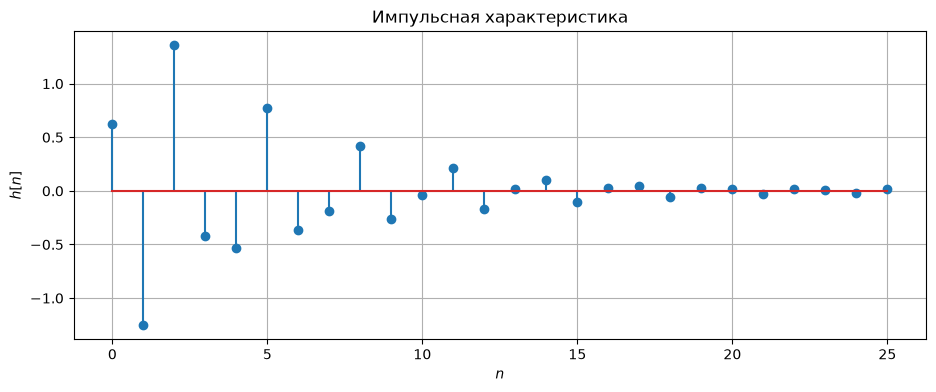

In [3]:
# Solve the difference equation sequentially with zero initial conditions
def recurrence(x_values, length):
    result = np.zeros(length)
    for n in range(length):
        for i in range(len(b)):
            if 0 <= n - i < len(x_values):
                result[n] += b[i] * x_values[n - i]
        for k in range(1, len(a)):
            if n >= k:
                result[n] -= a[k] * result[n - k]
        result[n] /= a[0]
    return result


h = recurrence([1.0], part1.N1)
poles = np.roots(a)


def g(n):
    return (
        (poles[0] ** (n + 1) - poles[1] ** (n + 1)) / (poles[0] - poles[1])
        if n >= 0
        else 0
    )


h_analytic = np.array([sum(b[i] * g(n - i) for i in range(3)) for n in range(part1.N1)])

np.testing.assert_allclose(h, h_analytic.real, atol=1e-13)
show_values("h", h)

fig, ax = plt.subplots()
stem_plot(ax, np.arange(len(h)), h, "Импульсная характеристика", "$n$", "$h[n]$")
plt.show()


Вычислены $N_1=26$ отсчётов. Полная импульсная характеристика бесконечна: полюсы ненулевые и не сокращаются нулями. Затухание отсчётов не означает, что характеристика становится строго нулевой.

#### 2
Вычислить реакцию $y_1[n]$ по формуле свёртки. В качестве воздействия $x[n]$ длины $N_2$ выбрать дискретный прямоугольный импульс:
$$
x[n] = 
\begin{cases}
1, && 0 \leq n < \text{int}(N_2 / 2) \\
0, && \text{int}(N_2 / 2) \leq n \leq N_2 - 1
\end{cases}
$$
где функция $\text{int}(t)$ -- округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:
1) чему равна длина импульса $x$;
2) чему равна длина свёртки аналитически и по графику;
3) почему её ограничивают до длины воздействия.

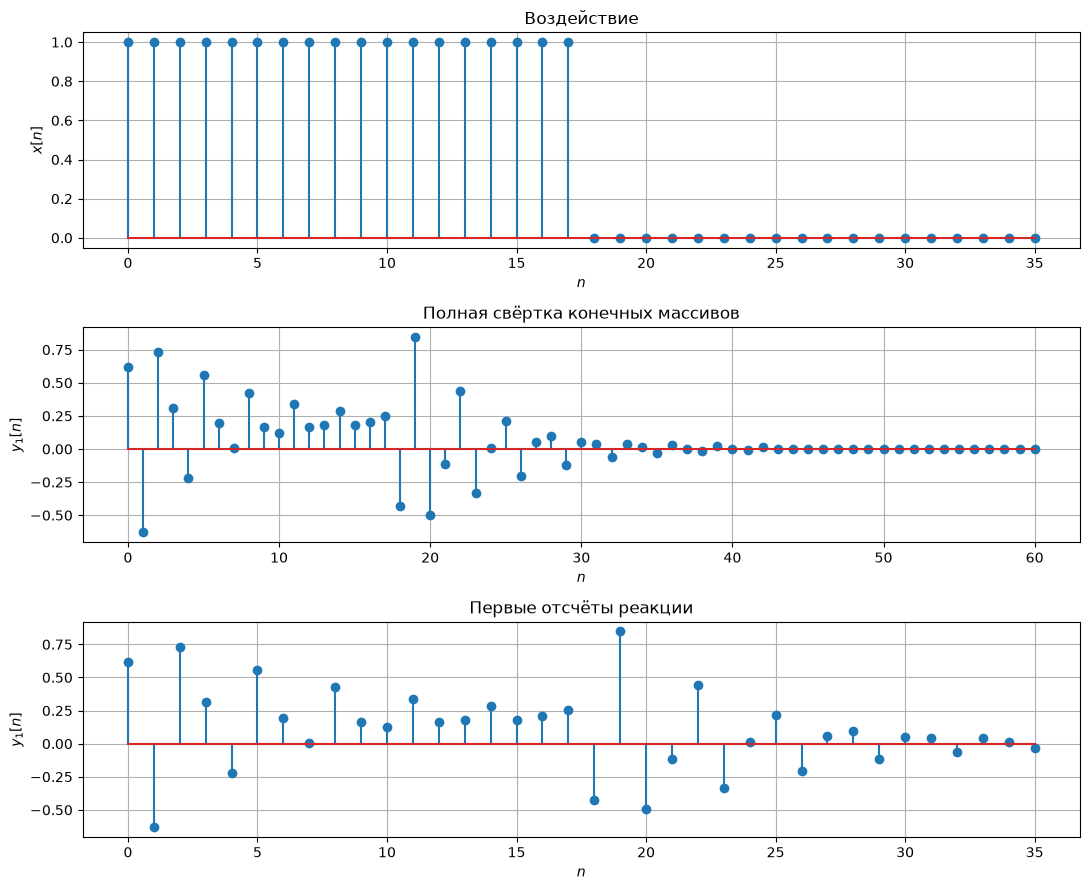

<IPython.core.display.Math object>

In [4]:
n_x = np.arange(part1.N2)
L = int(np.rint(part1.N2 / 2))
x = (n_x < L).astype(float)
y1_full = np.convolve(x, h, mode="full")
y1 = y1_full[: part1.N2]

fig, axes = plt.subplots(3, 1, figsize=(11, 9))
stem_plot(axes[0], n_x, x, "Воздействие", "$n$", "$x[n]$")
stem_plot(
    axes[1],
    np.arange(len(y1_full)),
    y1_full,
    "Полная свёртка конечных массивов",
    "$n$",
    "$y_1[n]$",
)
stem_plot(axes[2], n_x, y1, "Первые отсчёты реакции", "$n$", "$y_1[n]$")

plt.tight_layout()
plt.show()

display(Math(rf"N_x={len(x)},\quad L={L},\quad N_{{y_1}}={len(y1_full)}"))


Массив $x[n]$ имеет длину $N_2=36$, ненулевая часть прямоугольного импульса занимает $L=18$ отсчётов. Вне массива воздействие считается нулевым. Длина свёртки массивов равна $N_2+N_1-1=61$, но после последнего потенциально ненулевого отсчёта с номером $L+N_1-2=42$ идут нули. На графике ненулевая часть занимает до 43 отсчётов. Для полной бесконечной $h[n]$ реакция также бесконечна.

Ограничение результата первыми $N_2$ отсчётами задаёт общий интервал наблюдения для сравнения с входом и разностным уравнением.

#### 3
Вычислить реакцию $y_2[n]$ по разностному уравнению. Задать воздействие $x[n]$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1[n]$ и $y_2[n]$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

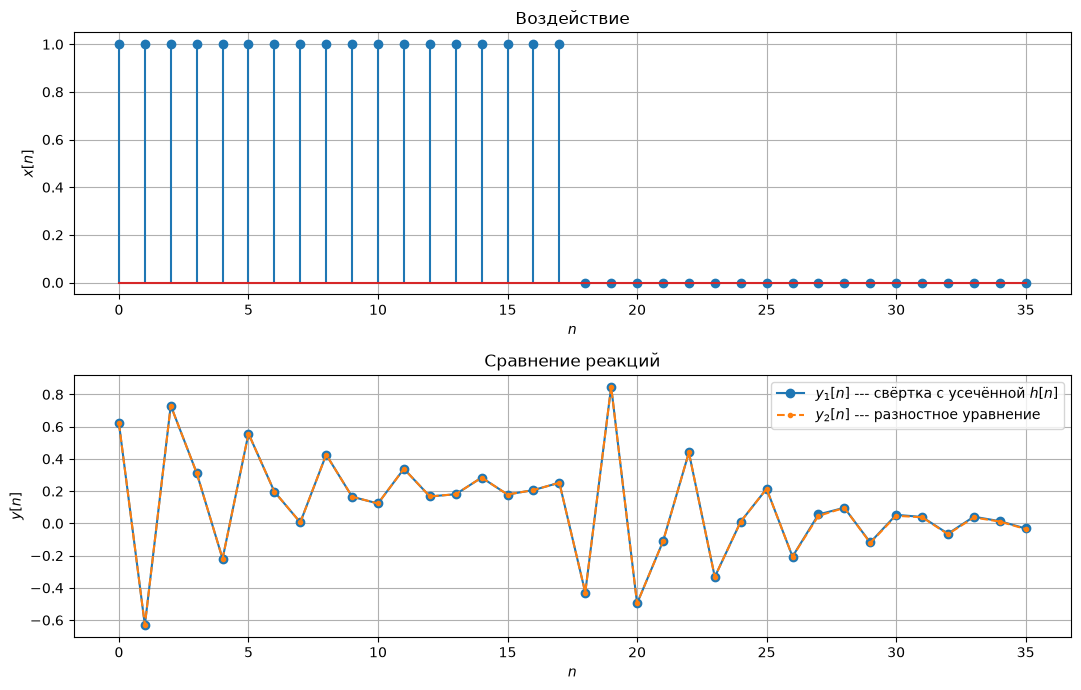

<IPython.core.display.Math object>

In [5]:
y2 = recurrence(x, part1.N2)
y2_tail = recurrence(x, 160)

# Convolution with enough impulse response samples must match the recurrence
h_long = recurrence([1.0], len(y2_tail))
y_exact = np.convolve(x, h_long)[: len(y2_tail)]

np.testing.assert_allclose(y_exact, y2_tail, atol=1e-13)
np.testing.assert_allclose(y1[: part1.N1], y2[: part1.N1], atol=1e-13)
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
stem_plot(axes[0], n_x, x, "Воздействие", "$n$", "$x[n]$")
axes[1].plot(n_x, y1, "o-", label="$y_1[n]$ --- свёртка с усечённой $h[n]$")
axes[1].plot(n_x, y2, ".--", label="$y_2[n]$ --- разностное уравнение")
axes[1].set(xlabel="$n$", ylabel="$y[n]$", title="Сравнение реакций")
axes[1].legend()

plt.tight_layout()
plt.show()

display(Math(rf"\max_{{0\leq n<N_2}}|y_1[n]-y_2[n]|={np.max(np.abs(y1-y2)):.6g}"))


С заданными коэффициентами
$$y[n]=0.62x[n]-0.67518x[n-1]+0.62x[n-2]-0.9278y[n-1]-0.676y[n-2].$$
Длина массива воздействия -- 36, ненулевая часть -- 18 отсчётов. Вычислены первые 36 отсчётов реакции, полная реакция бесконечна. До $n=25$ результаты совпадают с точностью округления. Начиная с $n=26$ свёртка с усечённой характеристикой теряет вклад её хвоста. Если для вычисления первых 36 отсчётов взять хотя бы 36 отсчётов $h[n]$, обе реализации совпадают с машинной точностью, что проверено выше.

#### 4
Вычислить нули и полюсы передаточной функции, нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

In [6]:
zeros = np.roots(b)

for symbol, roots in [("z", zeros), ("p", poles)]:
    for k, root in enumerate(roots):
        display(
            Math(
                rf"{symbol}_{{{k}}}={root.real:.8f}{root.imag:+.8f}j"
                rf"={abs(root):.8f}e^{{j({np.angle(root)/np.pi:.8f}\pi)}}"
            )
        )

factors_z = "".join(
    rf"(1-{abs(v):.8f}e^{{j({np.angle(v)/np.pi:.8f}\pi)}}z^{{-1}})" for v in zeros
)
factors_p = "".join(
    rf"(1-{abs(v):.8f}e^{{j({np.angle(v)/np.pi:.8f}\pi)}}z^{{-1}})" for v in poles
)

display(Math(rf"H(z)={b[0]:g}\frac{{{factors_z}}}{{{factors_p}}}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Корни найдены из $b_0z^2+b_1z+b_2=0$ и $z^2+a_1z+a_2=0$. Алгебраическая и показательная формы связаны равенствами $r=\sqrt{(\operatorname{Re}z)^2+(\operatorname{Im}z)^2}$, $\varphi=\operatorname{atan2}(\operatorname{Im}z,\operatorname{Re}z)$, $z=re^{j\varphi}$. Вещественные коэффициенты дают комплексно-сопряжённые пары. Для данного варианта нули лежат на единичной окружности, а полюсы имеют радиус $\sqrt{0.676}\approx0.82219$.

#### 5
Изобразить карту нулей и полюсов. Пояснить:
1) является ли рекурсивное звено устойчивым;
2) совпадают ли значения нулей и полюсов с вычисленными в п. 4.

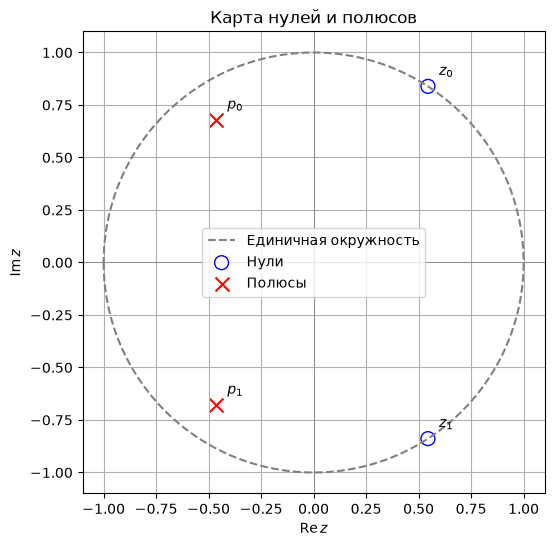

In [7]:
theta = np.linspace(-np.pi, np.pi, 600)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(np.cos(theta), np.sin(theta), "--", color="gray", label="Единичная окружность")
ax.scatter(
    zeros.real,
    zeros.imag,
    marker="o",
    facecolors="none",
    edgecolors="blue",
    s=100,
    label="Нули",
)
ax.scatter(poles.real, poles.imag, marker="x", color="red", s=100, label="Полюсы")

for symbol, roots in [("z", zeros), ("p", poles)]:
    for k, root in enumerate(roots):
        ax.annotate(
            rf"${symbol}_{k}$",
            (root.real, root.imag),
            xytext=(8, 8),
            textcoords="offset points",
        )
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set(
    xlabel=r"$\operatorname{Re}z$",
    ylabel=r"$\operatorname{Im}z$",
    title="Карта нулей и полюсов",
)
ax.set_aspect("equal")
ax.legend()
plt.show()
assert np.all(np.abs(poles) < 1)


Звено устойчиво: оба полюса строго внутри единичного круга. Точки карты построены по корням из п. 4 и совпадают с ними. Нули на окружности не нарушают устойчивость, но задают частоты полного подавления.

#### 6
Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat{\omega}$ и вывести их графики. Пояснить:
1) чему равны границы основной полосы частот;
2) соответствие между картой нулей и полюсов и видом АЧХ;
3) какому значению АЧХ соответствует скачок на $\pi$, если он имеется;
4) какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

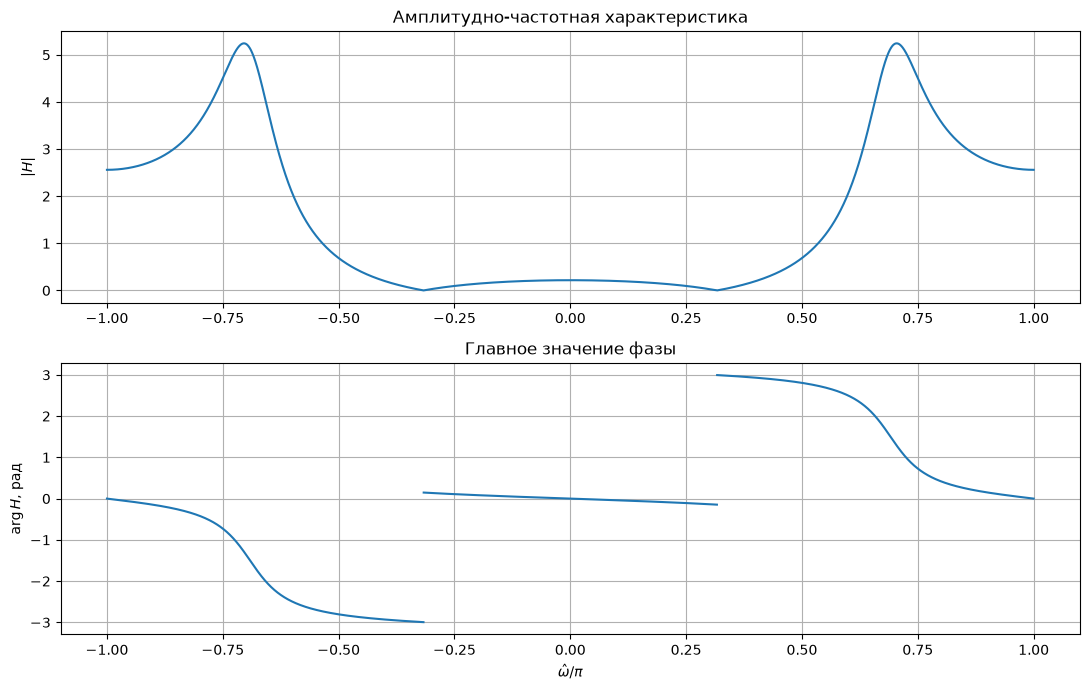

<IPython.core.display.Math object>

In [8]:
omega0 = abs(np.angle(zeros[0]))
omega = np.unique(np.r_[np.linspace(-np.pi, np.pi, 4097), -omega0, omega0])
_, H = signal.freqz(b, a, worN=omega)
phase_H = np.angle(H)
phase_H[np.abs(H) < 1e-10] = np.nan

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(omega / np.pi, np.abs(H))
axes[0].set(ylabel="$|H|$", title="Амплитудно-частотная характеристика")
axes[1].plot(omega / np.pi, phase_H)
axes[1].set(
    xlabel=r"$\hat\omega/\pi$", ylabel=r"$\arg H$, рад", title="Главное значение фазы"
)

plt.tight_layout()
plt.show()

_, H_limits = signal.freqz(b, a, worN=[0, omega0, np.pi])

display(
    Math(
        rf"\hat\omega_0={omega0/np.pi:.8f}\pi,\quad |H(0)|={abs(H_limits[0]):.6f},\quad |H(\pi)|={abs(H_limits[2]):.6f}"
    )
)


Основная полоса --- $[-\pi,\pi)$ рад/отсчёт; правый конец показан для наглядности периодичности. Нули на окружности создают провалы АЧХ до нуля при $\hat\omega=\pm\hat\omega_0$. Около углов полюсов возникают максимумы: знаменатель мал, когда точка $e^{j\hat\omega}$ приближается к полюсу. В точке нулевой АЧХ фаза не определена, а её односторонние пределы различаются на $\pi$. Перенос главного значения аргумента через границу $[-\pi,\pi]$ может дополнительно давать скачки на $2\pi$.

Звено преимущественно подавляет низкие частоты: усиление на нулевой частоте значительно меньше, чем на частоте Найквиста. Дополнительно полностью подавляются составляющие на частотах нулей; поэтому характеристика не является монотонной.

#### 7
Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_d$ и вывести их графики. Пояснить:
1) чему равны границы основной полосы частот;
2) соответствие частотами $\hat{\omega}$ и $f$.

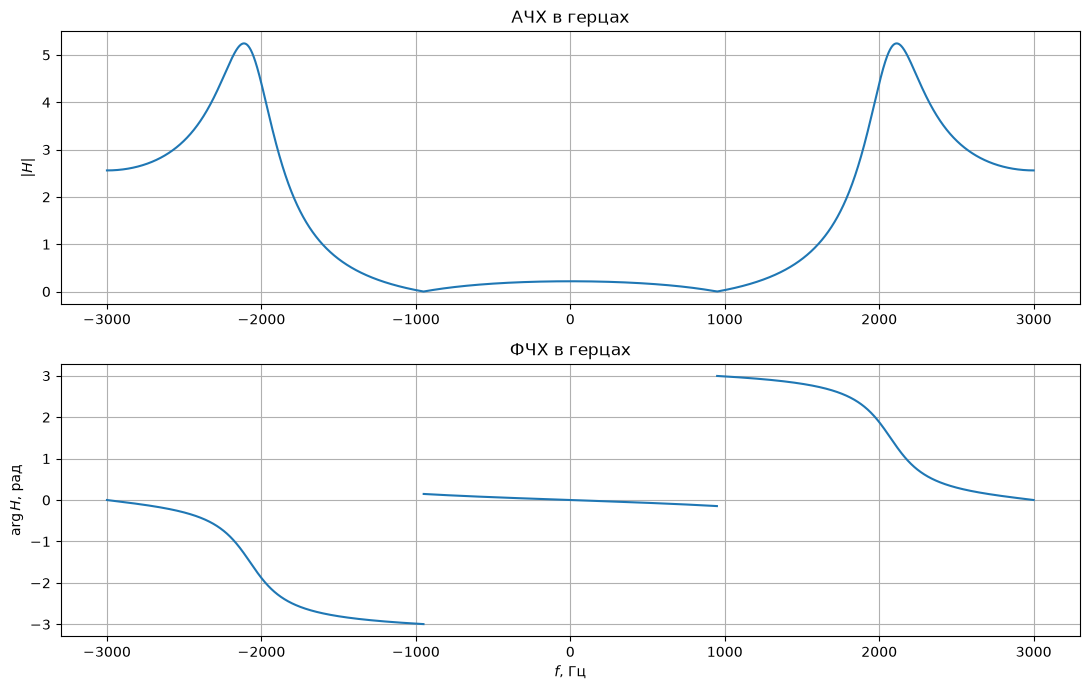

<IPython.core.display.Math object>

In [9]:
frequencies = omega * part1.fd / (2 * np.pi)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(frequencies, np.abs(H))
axes[0].set(ylabel="$|H|$", title="АЧХ в герцах")
axes[1].plot(frequencies, phase_H)
axes[1].set(xlabel="$f$, Гц", ylabel=r"$\arg H$, рад", title="ФЧХ в герцах")

plt.tight_layout()
plt.show()

display(Math(rf"f_0={omega0*part1.fd/(2*np.pi):.6f}\ \text{{Гц}}"))


При $f_d=6000$ Гц основная полоса равна $[-3000,3000)$ Гц. Связь шкал: $f=\hat\omega f_d/(2\pi)$, поэтому $\hat\omega=\pi$ соответствует $f=3000$ Гц. Форма характеристик сохраняется: меняется только масштаб горизонтальной оси.

## Часть 2

#### 1
Вычислить амплитудный и фазовый спектры периодической последовательности $x[n]$ с периодом $N$:
    $$
    x[nT]=A_1  cos(2 \pi f_1 nT + \pi / 4)+ A_2 cos(2 \pi f_2 n T + \pi / 8)
    $$
    Вывести графики последовательности x[n] на периоде $N$ в шкале дискретного и дискретного нормированного времени.

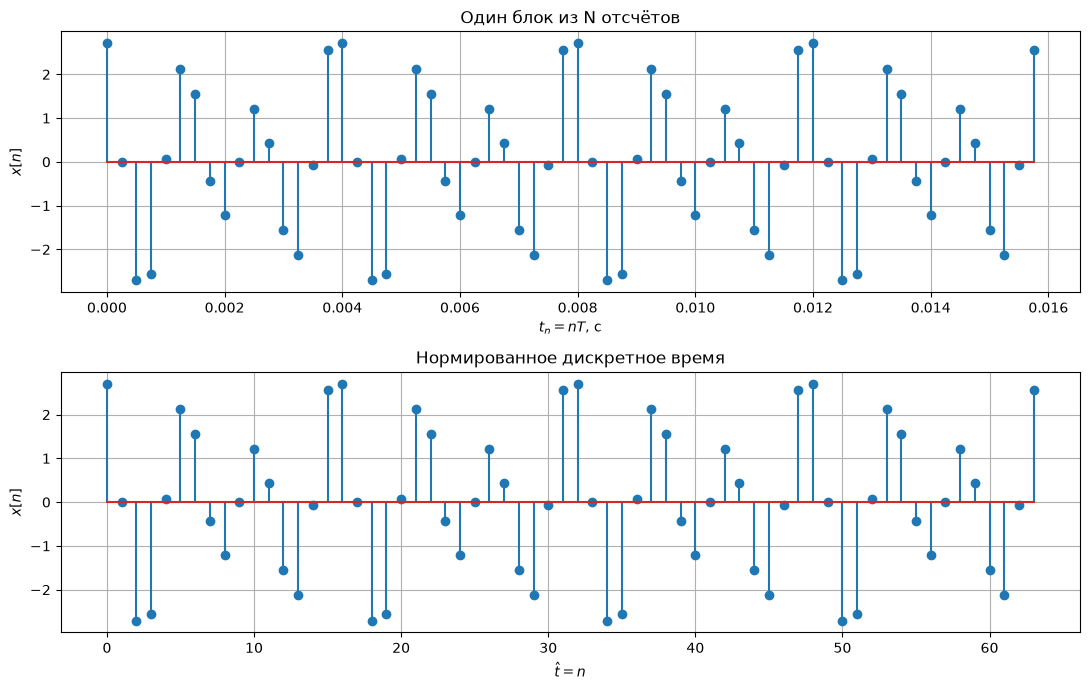

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [10]:
N, T = part2.N, part2.T
n = np.arange(N)
t_samples = n * T
x_period = part2.A1 * np.cos(
    2 * np.pi * part2.f1 * t_samples + np.pi / 4
) + part2.A2 * np.cos(2 * np.pi * part2.f2 * t_samples + np.pi / 8)
X = np.fft.fft(x_period)
C = X / N
amplitude = np.abs(C)
threshold = amplitude.max() * 1e-12
active = amplitude > threshold
phase = np.full(N, np.nan)
phase[active] = np.angle(C[active])

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
stem_plot(
    axes[0], t_samples, x_period, "Один блок из N отсчётов", "$t_n=nT$, с", "$x[n]$"
)
stem_plot(
    axes[1], n, x_period, "Нормированное дискретное время", r"$\hat t=n$", "$x[n]$"
)

plt.tight_layout()
plt.show()

for k in np.flatnonzero(active):
    display(
        Math(
            rf"|C_{{{k}}}|={amplitude[k]:.6g},\quad \arg C_{{{k}}}={phase[k]/np.pi:.6g}\pi"
        )
    )


Задано $f_d=4000$ Гц, $f_1=500$ Гц, $f_2=750$ Гц, $A_1=1.06$, $A_2=2.12$. Частоты точно попадают в бины $k_1=8$, $k_2=12$. Число $N=64$ является периодом последовательности; её минимальный период равен 16 отсчётам (НОД номеров гармоник 8 и 12 равен 4). Поэтому в блоке из 64 отсчётов видны четыре минимальных периода. Двусторонний спектр имеет линии высотой 0.53 при $k=8,56$ и 1.06 при $k=12,52$.

#### 2
Вычислить ОДПФ от ДПФ последовательности x[n] и вывести график полученной последовательности в шкале дискретного нормированного временах.

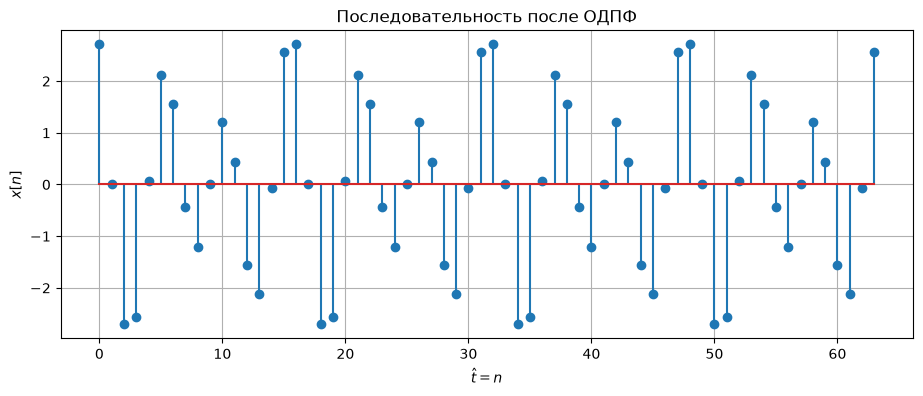

<IPython.core.display.Math object>

In [11]:
x_inverse = np.fft.ifft(X)
error_inverse = np.max(np.abs(x_inverse - x_period))

np.testing.assert_allclose(x_inverse, x_period, atol=1e-12)
fig, ax = plt.subplots()
stem_plot(
    ax, n, x_inverse.real, "Последовательность после ОДПФ", r"$\hat t=n$", "$x[n]$"
)
plt.show()

display(Math(rf"\max_n|x[n]-\operatorname{{IDFT}}(X)[n]|={error_inverse:.3g}"))


Обратное преобразование восстанавливает исходные отсчёты с погрешностью машинного округления; мнимая часть результата также имеет порядок ошибки округления.

#### 3
Вычислить амплитудный и фазовый спектры последовательности x(n) и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:
1) связь дискретного нормированного времени с дискретным временем;
2) связь частоты $f$ (Гц) с дискретной нормированной частотой;
3) вид амплитудного и фазового спектров.

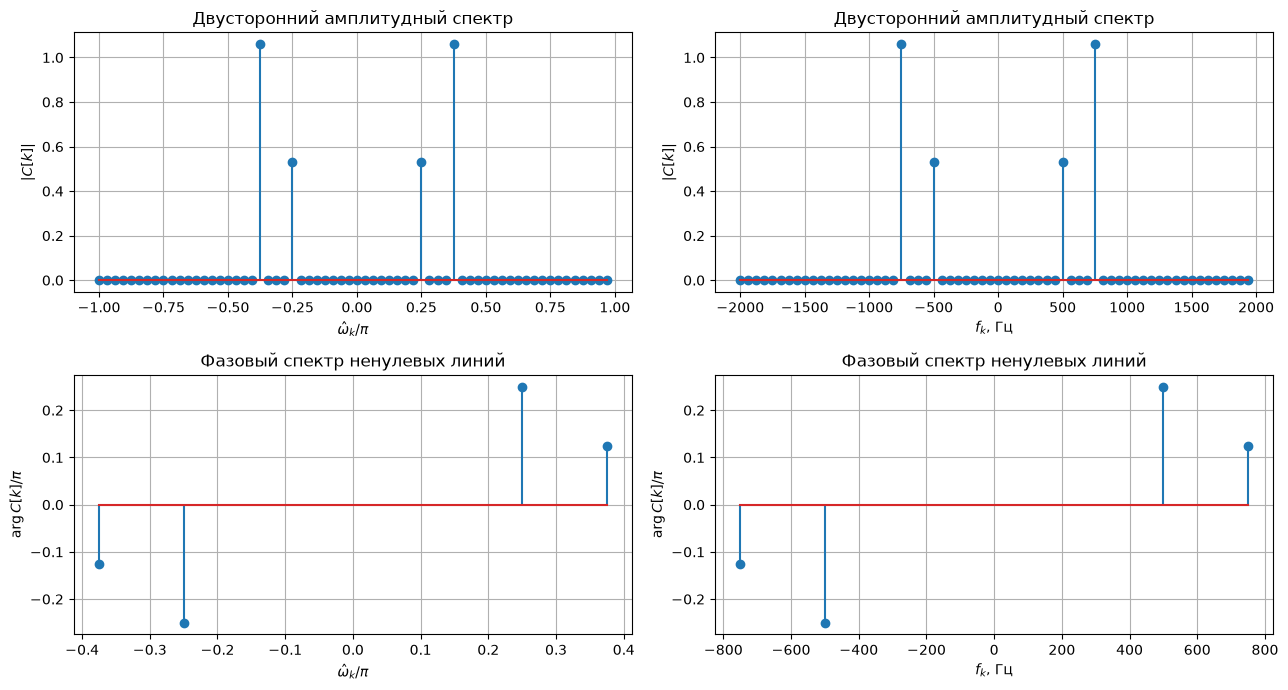

In [12]:
k_signed = np.arange(-N // 2, N // 2)
omega_k = 2 * np.pi * k_signed / N
f_k = k_signed * part2.fd / N
amplitude_center = np.fft.fftshift(amplitude)
phase_center = np.fft.fftshift(phase)
mask_center = np.isfinite(phase_center)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for column, (grid, label) in enumerate(
    [(omega_k / np.pi, r"$\hat\omega_k/\pi$"), (f_k, "$f_k$, Гц")]
):
    stem_plot(
        axes[0, column],
        grid,
        amplitude_center,
        "Двусторонний амплитудный спектр",
        label,
        "$|C[k]|$",
    )
    stem_plot(
        axes[1, column],
        grid[mask_center],
        phase_center[mask_center] / np.pi,
        "Фазовый спектр ненулевых линий",
        label,
        r"$\arg C[k]/\pi$",
    )

plt.tight_layout()
plt.show()


Нормированное время $\hat t=t/T$ принимает в отсчётах целые значения $n$. Нормированная угловая частота $\hat\omega_k=2\pi k/N$ связана с герцами как $f_k=\hat\omega_k f_d/(2\pi)$. Если нормировать частоту в циклах на отсчёт, $\nu_k=k/N=f_k/f_d$.

Спектр состоит из четырёх линий: при $f=\pm500$ Гц амплитуда равна $A_1/2=0.53$, при $f=\pm750$ Гц --- $A_2/2=1.06$. На положительных частотах фазы равны $\pi/4$ и $\pi/8$, на отрицательных --- $-\pi/4$ и $-\pi/8$. Амплитуда чётна, фаза нечётна вследствие вещественности сигнала. Спектральной утечки здесь нет, поскольку блок содержит целое число периодов обеих гармоник. Фазы остальных бинов не показаны: их амплитуды равны нулю с точностью округления.

#### 4
Вычислить ДПФ конечной последовательности $x[n]$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

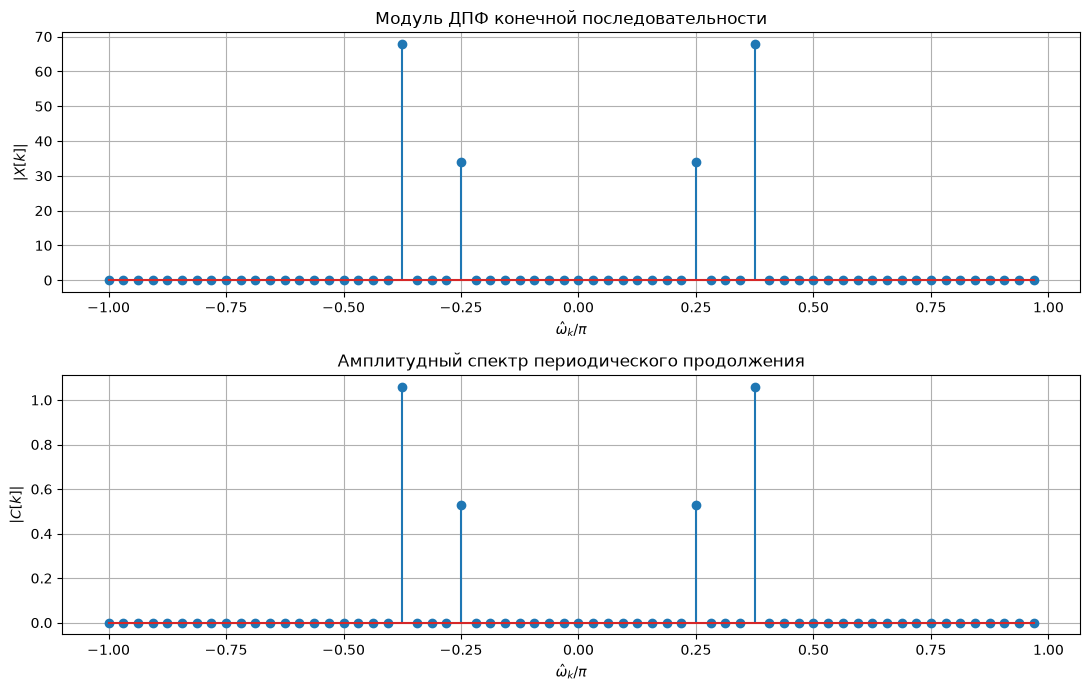

In [13]:
# Compute the DFT of the finite block directly from its definition
DFT_matrix = np.exp(-2j * np.pi * np.outer(np.arange(N), n) / N)
X_finite = DFT_matrix @ x_period

np.testing.assert_allclose(X_finite, X, atol=1e-11)
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
stem_plot(
    axes[0],
    omega_k / np.pi,
    np.abs(np.fft.fftshift(X_finite)),
    "Модуль ДПФ конечной последовательности",
    r"$\hat\omega_k/\pi$",
    "$|X[k]|$",
)
stem_plot(
    axes[1],
    omega_k / np.pi,
    amplitude_center,
    "Амплитудный спектр периодического продолжения",
    r"$\hat\omega_k/\pi$",
    "$|C[k]|$",
)

plt.tight_layout()
plt.show()


Для одного и того же блока значения ДПФ совпадают независимо от трактовки сигнала как конечного или периодического. Коэффициенты ряда Фурье периодической последовательности равны $C[k]=X[k]/N$, поэтому модуль ДПФ выше двустороннего амплитудного спектра в $N=64$ раза. Его ненулевые значения равны 33.92 и 67.84. ДПФ конечного блока --- дискретные частотные отсчёты его непрерывного по частоте преобразования Фурье; между ними у конечного блока возможны ненулевые значения, тогда как спектр периодического продолжения линейчатый.

#### 5
Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X(k)$ периодической последовательности $x[n]$. Для вычисления значений сигнала $x(t)$ использовать формулу
$$
x(t) = \cfrac{1}{N} \sum\limits_{k = -N / 2}^{N / 2 - 1} X_а(k) \exp(j \cfrac{2 \pi}{NT}kt),
$$
где отсчеты $X_а(k)$ связаны с отсчетами ДПФ $X(k)$ соотношением:
$$
X_а(k) =
\begin{cases}
X(N + k), && -N / 2 \leq k \leq -1 \\
X(k), && 0 \leq k \leq N / 2 - 1
\end{cases}
$$
задавая значения времени $t$ на интервале $t \in [0;(N-1)T]$ с шагом $\Delta t = 0.25 T$. Вывести графики:

1) периодической последовательности $x[n]$ и модуля ее ДПФ;
2) восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра;
4) исходного аналогового сигнала $x(t) = x[nT]\Big|_{t = nT}$.

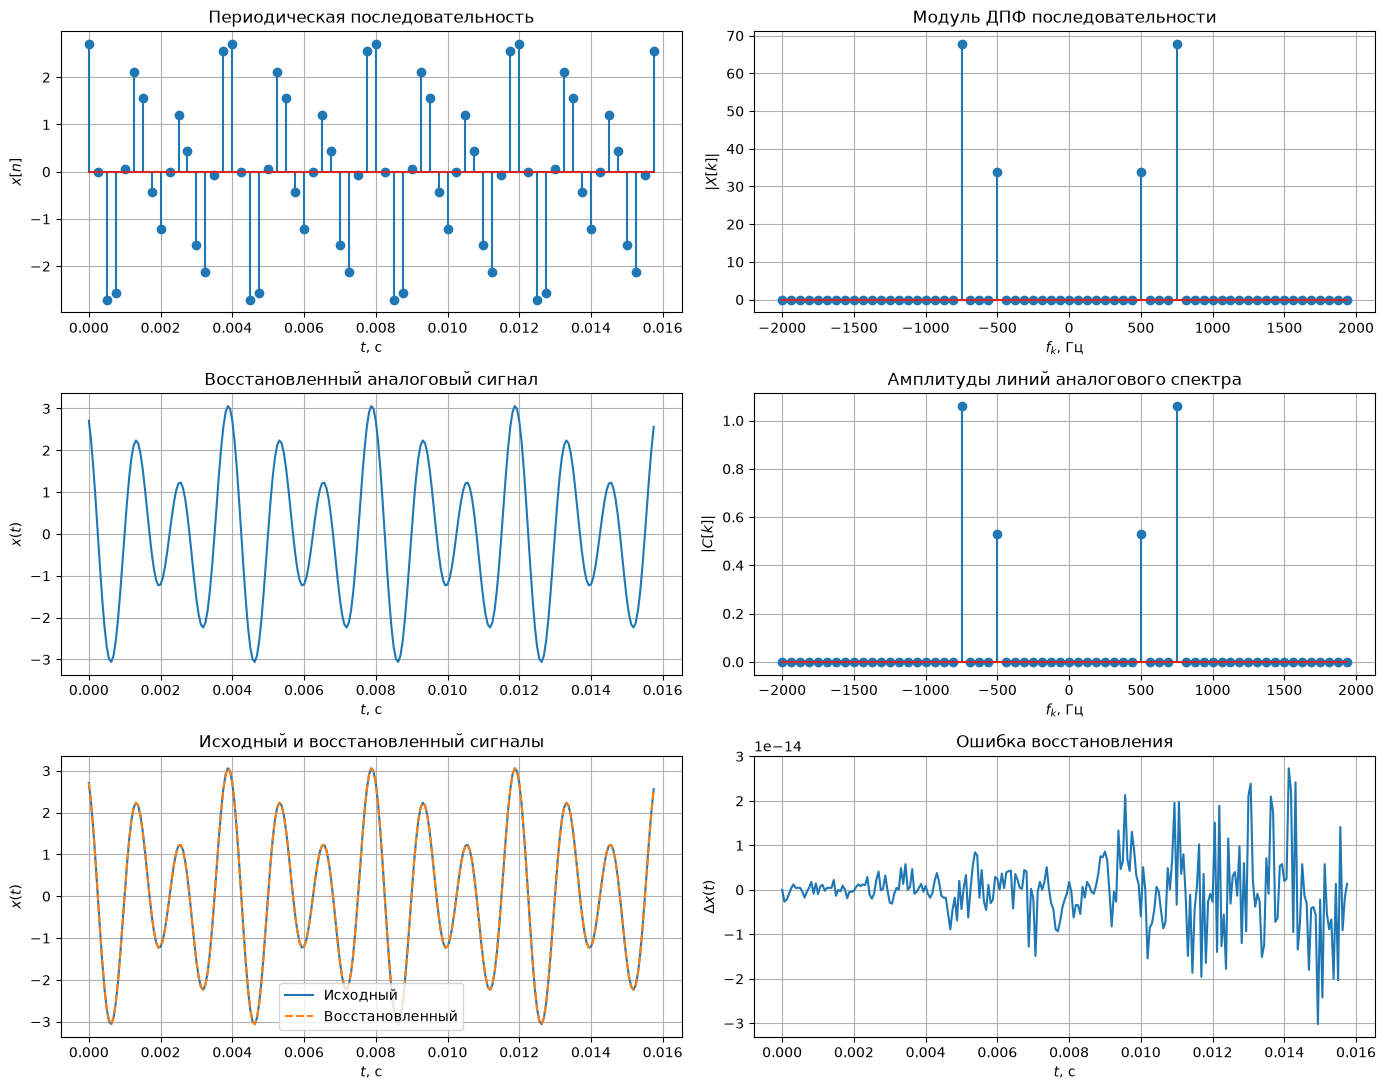

<IPython.core.display.Math object>

In [14]:
# Shift negative frequencies to the left half of the spectrum
X_a = np.fft.fftshift(X)
t_dense = np.arange(4 * (N - 1) + 1) * T / 4
basis = np.exp(2j * np.pi * np.outer(t_dense, k_signed) / (N * T))
x_restored_complex = basis @ X_a / N
x_restored = x_restored_complex.real
x_analog = part2.A1 * np.cos(
    2 * np.pi * part2.f1 * t_dense + np.pi / 4
) + part2.A2 * np.cos(2 * np.pi * part2.f2 * t_dense + np.pi / 8)

np.testing.assert_allclose(x_restored, x_analog, atol=1e-12)
np.testing.assert_allclose(x_restored[::4], x_period, atol=1e-12)
np.testing.assert_allclose(x_restored_complex.imag, 0, atol=1e-12)
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
stem_plot(
    axes[0, 0],
    t_samples,
    x_period,
    "Периодическая последовательность",
    "$t$, с",
    "$x[n]$",
)
stem_plot(
    axes[0, 1],
    f_k,
    np.abs(X_a),
    "Модуль ДПФ последовательности",
    "$f_k$, Гц",
    "$|X[k]|$",
)
axes[1, 0].plot(t_dense, x_restored)
axes[1, 0].set(
    title="Восстановленный аналоговый сигнал", xlabel="$t$, с", ylabel="$x(t)$"
)
stem_plot(
    axes[1, 1],
    f_k,
    np.abs(X_a) / N,
    "Амплитуды линий аналогового спектра",
    "$f_k$, Гц",
    "$|C[k]|$",
)
axes[2, 0].plot(t_dense, x_analog, label="Исходный")
axes[2, 0].plot(t_dense, x_restored, "--", label="Восстановленный")
axes[2, 0].set(
    title="Исходный и восстановленный сигналы", xlabel="$t$, с", ylabel="$x(t)$"
)
axes[2, 0].legend()
axes[2, 1].plot(t_dense, x_restored - x_analog)
axes[2, 1].set(title="Ошибка восстановления", xlabel="$t$, с", ylabel=r"$\Delta x(t)$")

plt.tight_layout()
plt.show()

display(
    Math(
        rf"\max_t|x_{{\mathrm{{восст}}}}(t)-x_{{\mathrm{{исх}}}}(t)|={np.max(np.abs(x_restored-x_analog)):.3g}"
    )
)


#### 6
Исходя из результатов п. 5, объяснить:
1) связь модуля ДПФ последовательности со спектром аналогового сигнала;
2) результат визуального сравнения восстановленного и исходного сигналов.

Восстановленный аналоговый сигнал содержит гармоники с комплексными коэффициентами $C[k]=X_a[k]/N$ и частотами $k/(NT)$. В соглашении $X(f)=\int x(t)e^{-j2\pi ft}dt$ его спектр равен $\sum_k C[k]\delta(f-k/(NT))$: на графике показаны модули весов дельта-линий, а не их конечная высота. Для одностороннего амплитудного спектра положительные линии нужно удвоить; получатся исходные амплитуды 1.06 и 2.12.

Исходный и восстановленный сигналы визуально совпадают, и численная проверка подтверждает совпадение на всей заданной сетке. Обе исходные частоты меньше $f_d/2=2000$ Гц и лежат на частотной сетке ДПФ. Преобразование не потеряло информацию о гармониках; различия обусловлены округлением. Составляющая Найквиста в этом варианте отсутствует.

#### 7
Проверить равенство Парсеваля. Пояснить его смысл.

In [15]:
energy_time = np.sum(np.abs(x_period) ** 2)
energy_frequency = np.sum(np.abs(X) ** 2) / N
power_time = energy_time / N
power_analytic = (part2.A1**2 + part2.A2**2) / 2

np.testing.assert_allclose(energy_time, energy_frequency, rtol=1e-13)
np.testing.assert_allclose(power_time, power_analytic, rtol=1e-13)
display(Math(rf"\sum_{{n=0}}^{{N-1}}|x[n]|^2={energy_time:.8f}"))

display(Math(rf"\frac1N\sum_{{k=0}}^{{N-1}}|X[k]|^2={energy_frequency:.8f}"))

display(Math(rf"P=\frac1N\sum_n|x[n]|^2=\sum_k|C[k]|^2={power_time:.8f}"))

display(Math(rf"|E_{{t}}-E_{{f}}|={abs(energy_time-energy_frequency):.3g}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Равенство Парсеваля выполнено: сумма квадратов отсчётов на блоке равна 179.776 в обеих областях. Средняя мощность равна 2.809 и совпадает с $(A_1^2+A_2^2)/2$. Преобразование меняет представление сигнала, сохраняя его энергию с учётом принятой нормировки. Для бесконечного периодического сигнала полная энергия бесконечна; здесь сравниваются энергия блока из 64 отсчётов и средняя мощность.

## Выводы
Вычислены импульсная характеристика, реакции на прямоугольный импульс, нули, полюсы и частотные характеристики рекурсивного звена. Звено устойчиво, имеет бесконечную затухающую импульсную характеристику и подавляет низкие частоты и частоты нулей. Свёртка и разностное уравнение дают одинаковую реакцию при достаточной длине используемой импульсной характеристики; её усечение объясняет расхождение на конце интервала наблюдения.

ДПФ выделило гармоники 500 и 750 Гц с заданными амплитудами и фазами. Установлена связь между модулем ДПФ конечного блока и коэффициентами Фурье периодического продолжения. Обратное ДПФ восстановило отсчёты, а сумма гармоник восстановила исходный аналоговый сигнал с точностью округления. Равенство Парсеваля подтверждено численно.